# Equipetrol Delivery · EC2 en Google Colab: P1 · las fases de los pedidos, AoS contra SoA (performance, 04)

Compila `delivery_sim` con CUDA, corre las pruebas de igualdad GPU = CPU en la GPU real, `compute-sanitizer`, mide
(esta aplicación: `--headless --bench`, un CSV), perfila con `nsys` y
`ncu`, corre la simulación de la ciudad y arma las tablas y los gráficos desde los CSV. Tarda unos 15 minutos.

**Antes de correr nada:** *Runtime → Change runtime type → T4 GPU → Save*. Cambiar el runtime borra los archivos:
después, *Runtime → Run all*. Todo corre en terminal: no hay ventana (`-DDELIVERY_WINDOW=OFF`, sin OpenCV).

Qué número sale de qué máquina (sección 2.2 del documento): las versiones de GPU salen de esta T4; el veredicto
compara contra la **CPU multihilo de la laptop** (su CSV está en el repo, en `docs/ec2/<aplicación>/laptop.csv`);
las versiones de CPU medidas acá dan la tabla secundaria "misma máquina".

**Al terminar:** descargar `results_p1_phases.zip` (lo baja la última celda) y el notebook ejecutado (*File → Download →
Download .ipynb*). **No usar "Guardar en GitHub":** haría un commit aparte en la rama.

In [1]:
# La máquina: GPU, driver, CUDA, compilador y CPU de Colab
!nvidia-smi --query-gpu=name,driver_version,clocks.max.sm,memory.total --format=csv
!nvcc --version | tail -2
!cmake --version | head -1
!g++ --version | head -1
!lscpu | grep -E 'Model name|^CPU\(s\)|Thread|Core'

name, driver_version, clocks.max.sm [MHz], memory.total [MiB]
Tesla T4, 580.82.07, 1590 MHz, 15360 MiB
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
cmake version 3.31.10
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      1


In [2]:
# El código: la rama de EC2 del repositorio (público). El hash de src/ no cambia con un --amend del mensaje:
# sirve para comprobar que lo medido es el código del commit.
BRANCH = "feat/ec2-gpu"
!rm -rf Delivery_Equipetrol && git clone -q -b {BRANCH} https://github.com/OjedaErwin123/Delivery_Equipetrol
!cd Delivery_Equipetrol && git log -1 --format='commit %h  %s' && echo "src/ = $(git rev-parse HEAD:src)"

commit 87b7f59  wip: P1 las fases de los pedidos en la GPU, AoS contra SoA (performance)
src/ = fcedcdc01436886c9518a20af809f5af33b5538a


In [3]:
# Compilar con CUDA (sm_75, la T4), Release, sin ventana. Unos minutos: Colab tiene 2 vCPU.
!cmake -S Delivery_Equipetrol -B build -DUSE_CUDA=ON -DDELIVERY_WINDOW=OFF -DCMAKE_BUILD_TYPE=Release 2>&1 | tail -3
!cmake --build build -j2 2>&1 | grep -iE 'warning|error|Built target (delivery_sim|gpu_)'

-- Configuring done (8.7s)
-- Generating done (0.2s)
-- Build files have been written to: /content/build
[ 15%] Built target delivery_sim
[ 48%] Built target gpu_smoke_check
[ 55%] Built target gpu_nearest_check
[ 59%] Built target gpu_apsp_check
[ 67%] Built target gpu_histogram_check
[ 74%] Built target gpu_grouping_check
[ 77%] Built target gpu_segment_stats_check
[ 82%] Built target gpu_slot_histogram_check
[ 87%] Built target gpu_heatmap_check
[ 92%] Built target gpu_coverage_check
[ 97%] Built target gpu_diffusion_check
[100%] Built target gpu_phases_check


## Pruebas: GPU = CPU en la GPU real

`ctest` corre todas las pruebas del proyecto. Las `gpu_*_check` comparan el resultado de cada kernel con la versión
de CPU (exacto en enteros; con tolerancia explicada en flotantes).

In [4]:
!cd build && ctest -j2 2>&1 | tail -3
!./build/gpu_phases_check

100% tests passed, 0 tests failed out of 55

Total Test time (real) =  26.80 sec
hasta 1000000 pedidos (GPU (nvcc))
AoS y SoA en la GPU = CPU (entregados y las tres sumas): OK
por el hilo dueño de la GPU: las mismas sumas: OK


## compute-sanitizer

`memcheck`: accesos fuera de rango o desalineados. `racecheck`: carreras en la memoria compartida (barreras que
faltan). Deben dar `ERROR SUMMARY: 0 errors` y `0 hazards`.

In [5]:
!compute-sanitizer --tool memcheck ./build/gpu_phases_check 2>&1 | tail -1
!compute-sanitizer --tool racecheck ./build/gpu_phases_check 2>&1 | tail -1

========= ERROR SUMMARY: 0 errors
========= RACECHECK SUMMARY: 0 hazards displayed (0 errors, 0 warnings)


## El bench: un CSV con una línea por corrida

Cada tamaño: una corrida de calentamiento de cada versión y después las repeticiones (15; 10 en T1) con las
versiones intercaladas. Cada corrida se compara con la referencia (columna `correct`).

In [6]:
!mkdir -p results
!./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-app p1_phases --bench results/colab.csv
!echo "corridas incorrectas: $(grep -c ',no,' results/colab.csv)"

bench: Intel(R) Xeon(R) CPU @ 2.00GHz x2 | Tesla T4, 15 repeticiones por tamaño
p1_phases n=1000: cpu_1=0.003423ms cpu_threadsx1=0.022201ms cpu_threadsx2=0.021324ms gpu_end_to_end=0.071624ms gpu_kernel=0.014336ms gpu_kernel_aos=0.010240ms gpu_via_owner=0.126174ms
p1_phases n=10000: cpu_1=0.037688ms cpu_threadsx1=0.092570ms cpu_threadsx2=0.057381ms gpu_end_to_end=0.134219ms gpu_kernel=0.011936ms gpu_kernel_aos=0.005888ms gpu_via_owner=0.304272ms
p1_phases n=100000: cpu_1=0.283440ms cpu_threadsx1=0.373676ms cpu_threadsx2=0.381812ms gpu_end_to_end=0.516220ms gpu_kernel=0.007776ms gpu_kernel_aos=0.010240ms gpu_via_owner=1.586345ms
p1_phases n=1000000: cpu_1=4.290425ms cpu_threadsx1=3.135801ms cpu_threadsx2=2.864634ms gpu_end_to_end=3.839220ms gpu_kernel=0.065056ms gpu_kernel_aos=0.121280ms gpu_via_owner=17.350625ms
p1_phases n=10000000: cpu_1=47.296234ms cpu_threadsx1=27.881837ms cpu_threadsx2=23.860592ms gpu_end_to_end=36.126288ms gpu_kernel=0.688128ms gpu_kernel_aos=1.171104ms gpu_via_ow

## Perfiles: nsys (línea de tiempo) y ncu (por kernel)

`nsys`: cuánto del tiempo de GPU es copia y cuánto kernel. `ncu`: ocupación (y su límite), rendimiento de memoria y
de cómputo, y los datos del roofline (una sola corrida: `--bench-once`; `ncu` fija el reloj de la GPU en su valor
base, así que sus duraciones son más largas que las del bench).

In [7]:
!nsys profile --stats=true --force-overwrite true -o results/timeline ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once --bench-app p1_phases 2>&1 | grep -A14 -E 'cuda_gpu_kern_sum|cuda_gpu_mem_time_sum' | head -45
print("===== phasesSoA con 10^7 pedidos (SoA, coalescido)")
!ncu --set full -k regex:phasesSoA --launch-skip 9 --launch-count 1 -f -o results/p1_phases_phasesSoA_0 ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once --bench-app p1_phases > /dev/null 2>&1
!ncu --import results/p1_phases_phasesSoA_0.ncu-rep --page details --section SpeedOfLight --section Occupancy --section LaunchStats --section MemoryWorkloadAnalysis --section WarpStateStats 2>&1 | grep -vE '^\s*$' | head -90
print("===== phasesAoS con 10^7 pedidos (AoS)")
!ncu --set full -k regex:phasesAoS --launch-skip 9 --launch-count 1 -f -o results/p1_phases_phasesAoS_1 ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once --bench-app p1_phases > /dev/null 2>&1
!ncu --import results/p1_phases_phasesAoS_1.ncu-rep --page details --section SpeedOfLight --section Occupancy --section LaunchStats --section MemoryWorkloadAnalysis --section WarpStateStats 2>&1 | grep -vE '^\s*$' | head -90

[6/8] Executing 'cuda_gpu_kern_sum' stats report

 Time (%)  Total Time (ns)  Instances  Avg (ns)   Med (ns)  Min (ns)  Max (ns)   StdDev (ns)                                                  Name                                                
 --------  ---------------  ---------  ---------  --------  --------  ---------  -----------  ----------------------------------------------------------------------------------------------------
     62.9        2,658,498         10  265,849.8  18,815.0     7,520  1,169,285    477,821.2  <unnamed>::phasesAoS(const OrderRecord *, unsigned int, unsigned long long *)                       
     37.1        1,567,579         10  156,757.9  12,447.5     7,520    688,880    279,596.8  <unnamed>::phasesSoA(const unsigned int *, const unsigned int *, const unsigned int *, const unsign…

[7/8] Executing 'cuda_gpu_mem_time_sum' stats report

 Time (%)  Total Time (ns)  Count   Avg (ns)    Med (ns)  Min (ns)   Max (ns)   StdDev (ns)            Operation   

## La simulación completa con la ciudad, en la T4

`delivery_sim` con la ciudad (3000 motos), sin ventana, 60 s reales. Las aplicaciones de tipo B corren dentro de la
simulación (R1 en el despachador, T1 al arrancar); las de tipo A, en el reporte del final (`--report`: relee el log
cuando la simulación terminó y no cambia nada de lo que pasó).

In [8]:
!./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --log results/events.log --report results/report.json > results/sim_out.txt 2> results/sim_err.txt; echo "salida: $?"
!head -6 results/sim_err.txt
!head -1 results/sim_out.txt && tail -1 results/sim_out.txt | cut -c1-200
import json
report = json.load(open("results/report.json"))
for name, part in report.items():
    print(name, {k: v for k, v in part.items() if not isinstance(v, list)})
!wc -l results/events.log && gzip -f results/events.log

salida: 0
delivery_sim: GPU: Tesla T4
delivery_sim: tabla de todos contra todos (4775 nodos) en la GPU: 314.288 ms de kernels, 417.829 ms en total
delivery_sim: sin ventana: --headless; la simulación sigue igual
delivery_sim: reporte en 'results/report.json'
Simulation has started...
{"created": 18215, "delivered": 964, "rejected": 16493, "pending": 758, "reassigned": 49, "breakdowns": 22, "avgDeliveryMs": 1761438, "maxDeliveryMs": 3409793, "deliveredPerCourier": {"c0": 5, "c1": 6
c1_demandHeatmap {'bounds': {'maxLat': -17.7565833, 'maxLon': -63.153827, 'minLat': -17.8101861, 'minLon': -63.209864}, 'computedOn': 'GPU (Tesla T4)', 'filter': {'sigmaCells': 2.0, 'taps': 13}, 'height': 128, 'ordersPlaced': 18215.0, 'smoothedTotal': 18215.000001063338, 'width': 128}
h1_deliveryTimes {'binMinutes': 1, 'computedOn': 'GPU (Tesla T4)', 'deliveredInLog': 964, 'lastBinIsAtLeastMinutes': 255, 'p50Minute': 29, 'p90Minute': 43, 'p99Minute': 50, 'total': 964}
h2_ordersPerSlot {'computedOn': 'GPU (Tes

## Tablas y gráficos (desde los CSV, nada escrito a mano)

Mediana [mín–máx] por versión y tamaño. El veredicto compara la GPU de punta a punta con la mejor CPU multihilo de la
**laptop**; la tabla de Colab-CPU es la comparación en la misma máquina.

In [9]:
import pandas as pd, matplotlib.pyplot as plt, pathlib
colab = pd.read_csv("results/colab.csv")
laptop_files = list(pathlib.Path("Delivery_Equipetrol/docs/ec2").glob("*/laptop.csv"))
laptop = pd.concat([pd.read_csv(f) for f in laptop_files]) if laptop_files else colab.iloc[0:0]
laptop = laptop[laptop.application.isin(colab.application.unique())]
print("laptop:", laptop["machine"].iloc[0] if len(laptop) else "(todavía sin CSV de la laptop para esta aplicación)")
print("colab: ", colab["machine"].iloc[0])

def summary(df):
    g = df.groupby(["application", "version", "threads", "size"])["ms"]
    return g.agg(median="median", min="min", max="max", runs="count").reset_index()

def best_cpu(s):
    cpu = s[s.version.isin(["cpu_1", "cpu_threads"])]
    return cpu.loc[cpu.groupby(["application", "size"])["median"].idxmin()].set_index(["application", "size"])

def table(app, cpu_source):
    s_cpu, s_gpu = summary(cpu_source), summary(colab)
    rows = []
    for size in sorted(s_gpu[s_gpu.application == app]["size"].unique()):
        pick = lambda s, v: s[(s.application == app) & (s.version == v) & (s["size"] == size)]
        best = best_cpu(s_cpu).loc[(app, size)]
        kern = pick(s_gpu, "gpu_kernel")["median"].min()
        e2e = pick(s_gpu, "gpu_end_to_end")["median"].min()
        ok = (cpu_source[(cpu_source.application == app) & (cpu_source["size"] == size)].correct == "yes").all() and \
             (colab[(colab.application == app) & (colab["size"] == size)].correct == "yes").all()
        rows.append({"size": size, "CPU 1 hilo (ms)": pick(s_cpu, "cpu_1")["median"].min(),
                     "mejor CPU (ms)": best["median"], "N": int(best["threads"]),
                     "GPU kernel (ms)": kern, "GPU punta a punta (ms)": e2e,
                     "speedup kernel": best["median"] / kern, "speedup punta a punta": best["median"] / e2e,
                     "correcto": "sí" if ok else "NO"})
    return pd.DataFrame(rows)

for app in sorted(colab.application.unique()):
    if len(laptop[laptop.application == app]):
        print(f"\n=== {app}: GPU contra la CPU de la laptop (veredicto) ===")
        display(table(app, laptop[laptop.application == app]).round(4))
    print(f"=== {app}: GPU contra la CPU de Colab (misma máquina) ===")
    display(table(app, colab).round(4))

laptop: (todavía sin CSV de la laptop para esta aplicación)
colab:  Intel(R) Xeon(R) CPU @ 2.00GHz x2 | Tesla T4
=== p1_phases: GPU contra la CPU de Colab (misma máquina) ===


,size,CPU 1 hilo (ms),mejor CPU (ms),N,GPU kernel (ms),GPU punta a punta (ms),speedup kernel,speedup punta a punta,correcto
0,1000,0.0034,0.0034,1,0.0143,0.0716,0.2388,0.0478,sí
1,10000,0.0377,0.0377,1,0.0119,0.1342,3.1575,0.2808,sí
2,100000,0.2834,0.2834,1,0.0078,0.5162,36.4506,0.5491,sí
3,1000000,4.2904,2.8646,2,0.0651,3.8392,44.0333,0.7461,sí
4,10000000,47.2962,23.8606,2,0.6881,36.1263,34.6747,0.6605,sí


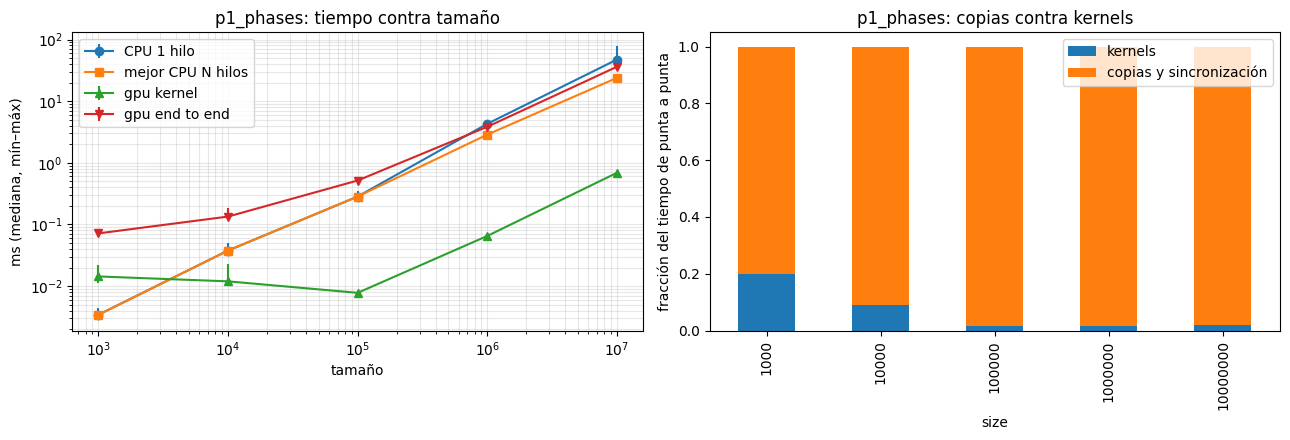

In [10]:
# Gráfico 1: tiempo contra tamaño, las cuatro versiones, log-log, con el cruce. Gráfico 2: copias contra kernels.
for app in sorted(colab.application.unique()):
    lap = laptop[laptop.application == app]
    cpu_src = lap if len(lap) else colab[colab.application == app]
    s_cpu, s_gpu = summary(cpu_src), summary(colab[colab.application == app])
    best = best_cpu(s_cpu).reset_index()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    one = s_cpu[s_cpu.version == "cpu_1"]
    ax[0].errorbar(one["size"], one["median"], yerr=[one["median"] - one["min"], one["max"] - one["median"]], marker="o", label="CPU 1 hilo")
    ax[0].errorbar(best["size"], best["median"], marker="s", label="mejor CPU N hilos")
    for v, m in (("gpu_kernel", "^"), ("gpu_end_to_end", "v")):
        g = s_gpu[s_gpu.version == v]
        ax[0].errorbar(g["size"], g["median"], yerr=[g["median"] - g["min"], g["max"] - g["median"]], marker=m, label=v.replace("_", " "))
    e2e = s_gpu[s_gpu.version == "gpu_end_to_end"].set_index("size")["median"]
    b = best.set_index("size")["median"]
    wins = [n for n in e2e.index if n in b.index and e2e[n] < b[n]]
    if wins:
        ax[0].axvline(min(wins), color="gray", ls="--", label=f"cruce: {min(wins)}")
    ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("tamaño"); ax[0].set_ylabel("ms (mediana, mín–máx)")
    ax[0].set_title(f"{app}: tiempo contra tamaño"); ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)
    kern = s_gpu[s_gpu.version == "gpu_kernel"].set_index("size")["median"]
    pd.DataFrame({"kernels": kern / e2e, "copias y sincronización": 1 - kern / e2e}).plot.bar(stacked=True, ax=ax[1])
    ax[1].set_ylabel("fracción del tiempo de punta a punta"); ax[1].set_title(f"{app}: copias contra kernels")
    plt.tight_layout(); plt.savefig(f"results/{app}.png", dpi=120); plt.show()

In [11]:
# Barrido de hilos de la CPU multihilo (speedup contra 1 hilo de la misma versión), en la laptop si está y en Colab.
for name, df in (("laptop", laptop), ("colab", colab)):
    s = summary(df[df.version == "cpu_threads"])
    for app in sorted(s.application.unique()):
        piv = s[s.application == app].pivot(index="size", columns="threads", values="median")
        display((piv[1].values[:, None] / piv).round(2).rename_axis(f"{name} {app}: speedup contra 1 hilo", axis=1))

colab p1_phases: speedup contra 1 hilo,1,2
size,,
1000,1.0,1.04
10000,1.0,1.61
100000,1.0,0.98
1000000,1.0,1.09
10000000,1.0,1.17


## Guardar los resultados

Colab borra todo al cerrar la sesión. La celda arma `results_p1_phases.zip` (CSV, gráficos, reportes de nsys y ncu, la
simulación) y lo descarga. Para guardarlo también en Google Drive, cambiar `GUARDAR_EN_DRIVE` a `True` (Colab pide
permiso la primera vez): queda en `MyDrive/EC2_resultados/`.

In [12]:
GUARDAR_EN_DRIVE = False
!cd Delivery_Equipetrol && git rev-parse HEAD:src > ../results/src_tree.txt
!zip -qr results_p1_phases.zip results && ls -la results_p1_phases.zip
if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    !mkdir -p /content/drive/MyDrive/EC2_resultados && cp results_p1_phases.zip /content/drive/MyDrive/EC2_resultados/
from google.colab import files
files.download("results_p1_phases.zip")

-rw-r--r-- 1 root root 780824 Nov 20 21:52 results_p1_phases.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>